# BSISO_ERE_Link: results

How the BSISO organises large extreme-rain events (EREs) over India, and what that means for forecasting them.
JJAS (June-September) 2000-2024, IMERG rainfall at 0.25 degree.

**The event.** An ERE is a group of at least 16 connected IMERG cells (about 12,000 km2), each above its own
wet-day 99th percentile. The study event is a day with at least one such ERE centred in central India
(17-26.5N, 74-88.5E). Forecast tests are out of sample (each summer predicted from the other 24). p-values come
from re-dating whole seasons (each summer gets another summer's BSISO), never from textbook formulas.

**Contents**
1. Data and the extreme-rain objects
2. Why this ERE definition (figure 1)
3. Bayes view: how the BSISO changes the odds, and when (figure 2)
4. Probability maps for each BSISO phase (figure 3)
5. Clustering compared with active and break spells (figure 4)
6. Where the events sit in each phase (figure 5)
7. ERE tracks on the BSISO phase plane: longest tracks, starts, size classes, average path (figures 6-9)
8. Does a stronger BSISO matter? (figure 10)
9. The forecast target: daily ERE size class (figure 11)

## 0. Setup and data

In [1]:
# %% CELL 1 -- setup and data
import os, glob, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import ndimage
from IPython.display import display

warnings.filterwarnings("ignore")
ROOTS = [r for r in os.environ.get("BSISO_DATA", "/kaggle/input").split(os.pathsep) if r]
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)


def find(pattern, required=True):
    for r in ROOTS:
        hits = sorted(glob.glob(os.path.join(r, "**", pattern), recursive=True))
        if hits:
            return hits[0]
    if required:
        raise FileNotFoundError(f"{pattern} not found in the attached datasets")
    return None


SURF, INK, INK2, GRID, NULLC = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#d9d8d3"
BLUE, BROWN, ORANGE, GREEN, PURPLE = "#2a78d6", "#8a5a19", "#d4572a", "#1baf7a", "#7b5ea7"
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True})

ds = xr.open_dataset(find("imerg_india_025_jjas_2000_2024.nc"))
tp = ds["tp"].values.astype("float32")
lat, lon = ds["lat"].values, ds["lon"].values
times = pd.DatetimeIndex(ds["time"].values).normalize()
ds.close()
years, keys = times.year.values, times.strftime("%m%d").values
kidx = np.searchsorted(np.array(sorted(set(keys))), keys)
NYR, ND = len(np.unique(years)), len(set(keys))
mask = np.load(find("india_mask_025.npy"))
assert mask.shape == tp.shape[1:]

b = pd.read_csv(find("BSISO.INDEX.NORM.LY.data"), sep=r"\s+", skiprows=1, header=None,
                names=["year", "doy", "p1", "p2", "q1", "q2", "a1", "a2"])
b["date"] = pd.to_datetime(b["year"].astype(str), format="%Y") + pd.to_timedelta(b["doy"] - 1, unit="D")
for c in ("p1", "p2"):
    b.loc[b[c] <= -999, c] = np.nan
b[["p1", "p2"]] = b[["p1", "p2"]].interpolate(limit=1)
bs = b.set_index("date")[["p1", "p2"]]
PC1, PC2 = bs["p1"].reindex(times).values, bs["p2"].reindex(times).values
AMP = np.hypot(PC1, PC2)
THETA = np.mod(np.arctan2(PC1, -PC2), 2 * np.pi)                 # phase convention: India = phases 4-6
PHASE = (np.floor(THETA / (np.pi / 4)) + 1).astype(int)
PH = np.where(AMP >= 1, PHASE, 0)                                 # 0 = BSISO weak (amplitude < 1)
INDIA = AMP * np.cos(THETA - np.deg2rad(202.5))                  # projection on the phase-5 direction ("BSISO over India")

rng = np.random.default_rng(2026)
NPERM = 1000
PERMS = [rng.permutation(NYR) for _ in range(NPERM)]             # season re-dating: each summer gets another's BSISO
redate = lambda x, p: x.reshape(NYR, ND)[p].ravel()
print(f"IMERG JJAS {years.min()}-{years.max()}, {len(times):,} days | BSISO weak on {np.mean(PH == 0):.0%} of days")

IMERG JJAS 2000-2024, 3,050 days | BSISO weak on 33% of days


## 1. Extreme-rain objects and spells, rebuilt from IMERG

In [2]:
# %% CELL 2 -- rebuild the extreme-rain objects and the active/break spells from IMERG
THR = np.maximum(np.nanpercentile(np.where(tp > 1, tp, np.nan), 99, axis=0), 50).astype("float32")
LA2, LO2 = np.meshgrid(lat, lon, indexing="ij")
CELL_KM2 = (111.2 * 0.25) ** 2 * np.cos(np.deg2rad(LA2))         # area of each 0.25 deg cell
LABELS = np.zeros(tp.shape, dtype=np.int32)                       # object labels, kept for the maps
rows = []
for t in range(len(times)):
    L, n = ndimage.label(mask & (tp[t] > THR), structure=np.ones((3, 3)))
    LABELS[t] = L
    if n:
        idx = np.arange(1, n + 1)
        rows.append(pd.DataFrame({"t": t, "lbl": idx, "size": ndimage.sum(np.ones_like(THR), L, idx).astype(int),
                                  "area_km2": ndimage.sum(CELL_KM2, L, idx),
                                  "clat": ndimage.mean(LA2, L, idx), "clon": ndimage.mean(LO2, L, idx),
                                  "max_mm": ndimage.maximum(tp[t], L, idx)}))
OB = pd.concat(rows, ignore_index=True)


def region_of(la, lo):                                            # identical to the summer pipeline
    if lo >= 88.5 and 21.5 <= la <= 29.5:
        return "Northeast"
    if lo <= 77.5 and 8.0 <= la <= 21.0:
        return "Western Ghats"
    if la >= 26.5:
        return "Himalayan foothills"
    if 17.0 <= la < 26.5 and 74.0 <= lo <= 88.5:
        return "Central India"
    return "Other"


OB["region"] = [region_of(a, o) for a, o in zip(OB["clat"], OB["clon"])]
BIG = OB[OB["size"] >= 16]                                        # the study's EREs: 16+ cells (~12,000 km2)
inbig = np.zeros(tp.shape, bool)                                  # cell inside a 16+ cell ERE that day (for the maps)
for t, g in BIG.groupby("t"):
    inbig[t] = np.isin(LABELS[t], g["lbl"].values)


def days_with(sel):
    v = np.zeros(len(times), bool)
    v[sel["t"].values] = True
    return v


def run_starts(v):
    """First day of each run of consecutive event days (within a season): counts an event once."""
    prev = np.r_[False, v[:-1]] & (np.r_[0, np.diff(years)] == 0)
    return v & ~prev


EV = {r: days_with(BIG[BIG["region"] == r]) for r in ("Central India", "Northeast")}
STARTS = {r: run_starts(v) for r, v in EV.items()}

# spells (project recipe): central-India land 18-28N, 73-88E; +-1 sd of the calendar-day climatology, >= 3 days
box = mask & (((lat >= 18) & (lat <= 28))[:, None] & ((lon >= 73) & (lon <= 88))[None, :])
cmz = tp[:, box].mean(axis=1)
df_ = pd.DataFrame({"x": cmz, "k": kidx})
mu = df_.groupby("k").x.mean().rolling(15, center=True, min_periods=1).mean().values
sd = df_.groupby("k").x.std().rolling(15, center=True, min_periods=1).mean().values
Z = (cmz - mu[kidx]) / sd[kidx]
CMZ_ANOM = cmz - mu[kidx]


def spells(cond):
    lab, i = np.zeros(len(cond), bool), 0
    while i < len(cond):
        if cond[i]:
            j = i
            while j + 1 < len(cond) and cond[j + 1] and years[j + 1] == years[i]:
                j += 1
            if j - i + 1 >= 3:
                lab[i:j + 1] = True
            i = j + 1
        else:
            i += 1
    return lab


ACT, BRK = spells(Z >= 1), spells(Z <= -1)
display(pd.DataFrame({
    "count": [len(OB), len(BIG), int(EV["Central India"].sum()), int(STARTS["Central India"].sum()),
              int(EV["Northeast"].sum()), int(STARTS["Northeast"].sum()), int(ACT.sum()), int(BRK.sum())]},
    index=["extreme-rain objects (all sizes)", "objects of 16+ cells", "Central India: days with a 16+ cell ERE",
           "Central India: ERE events (first days)", "Northeast: days with a 16+ cell ERE", "Northeast: ERE events",
           "active spell days", "break spell days"]))

,count
extreme-rain objects (all sizes),10873
objects of 16+ cells,1096
Central India: days with a 16+ cell ERE,468
Central India: ERE events (first days),254
Northeast: days with a 16+ cell ERE,122
Northeast: ERE events,85
active spell days,285
break spell days,304


## 2. Why this ERE definition?
Information (bits per day) that the BSISO 5 days earlier adds to the seasonal chance, for several candidate events, and for other thresholds and sizes.

,days per summer,bits per day,90% range
event,,,
active spell day,11.4,0.0163,0.0023-0.0295
box-mean rain in its top 20%,24.4,0.0180,0.0055-0.0290
any-size p99 cluster,64.8,0.0080,0.0016-0.0142
Nikumbh-style 1 deg box > p99.5,20.5,0.0284,0.0149-0.0417
16+ cell ERE (this study),18.7,0.0303,0.0156-0.0447


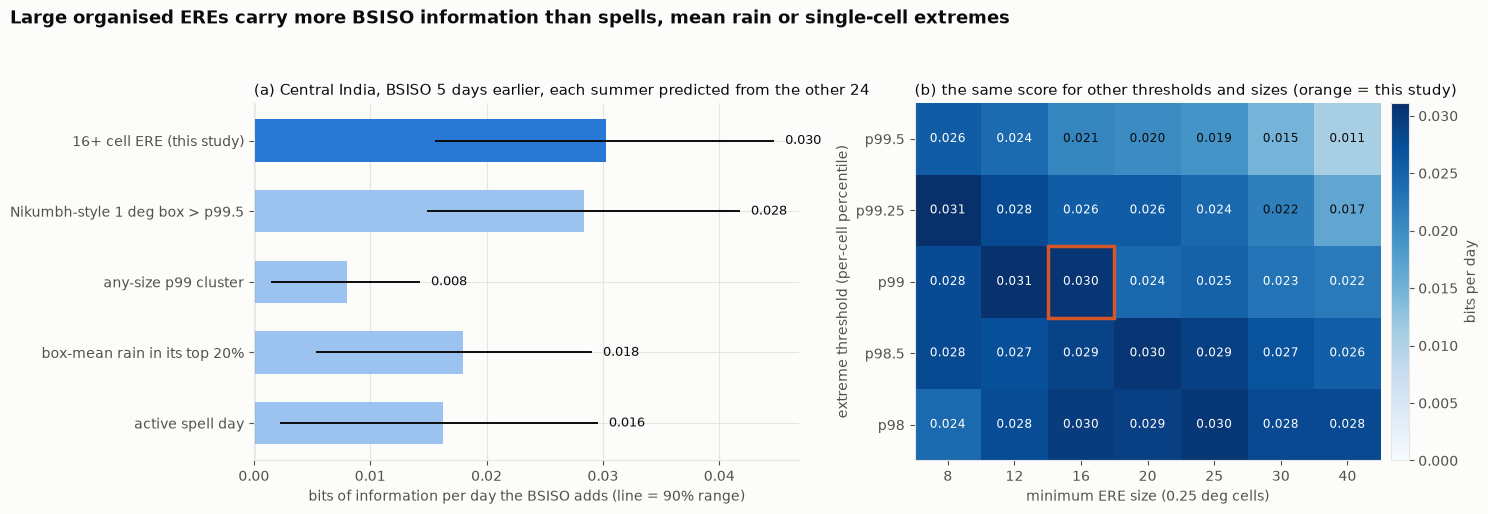

In [3]:
# %% CELL 3 -- FIGURE 1: why this ERE definition? (how much each candidate event tells us about the BSISO)
# The study event: a day with at least one 16+ cell ERE centred in Central India (EV["Central India"]).
# Score = information gain: how many bits per day the BSISO (5 days earlier) adds to the seasonal chance,
# out of sample (each summer predicted from the other 24). 0 = the BSISO adds nothing.
def feats(x1, x2):
    return np.column_stack([x1, x2, np.hypot(x1, x2)])


def true_at(off):                                                # observed BSISO on day t + off
    v = bs.reindex(times + pd.Timedelta(days=off)).values
    return feats(v[:, 0], v[:, 1])


lz_path = find("lasso_bsiso_forecasts.parquet", required=False)
LZ = pd.read_parquet(lz_path).set_index(["lead", "target"])[["f1", "f2"]] if lz_path else None


def lasso_at(lead, off):                                         # lasso forecast of day t + off, made `lead` days earlier
    idx = pd.MultiIndex.from_arrays([np.full(len(times), lead), times + pd.Timedelta(days=off)])
    v = LZ.reindex(idx).values
    return feats(v[:, 0], v[:, 1])


def fit_predict(Xtr, ytr, Xte, l2=1e-3):
    Xtr = np.column_stack([np.ones(len(Xtr)), Xtr]); Xte = np.column_stack([np.ones(len(Xte)), Xte])
    w = np.zeros(Xtr.shape[1]); R_ = l2 * np.diag(np.r_[0, np.ones(len(w) - 1)])
    for _ in range(30):
        p = 1 / (1 + np.exp(-np.clip(Xtr @ w, -30, 30)))
        step = np.linalg.solve((Xtr * (p * (1 - p))[:, None]).T @ Xtr + R_, Xtr.T @ (p - ytr) + R_ @ w)
        w -= step
        if np.abs(step).max() < 1e-7:
            break
    return 1 / (1 + np.exp(-np.clip(Xte @ w, -30, 30)))


def loyo(y, X):
    """Leave-one-year-out: reference = seasonal climatology (training years); model = climatology + BSISO."""
    good = ~np.isnan(y) & ~np.isnan(X).any(axis=1)
    pm, pr = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for yr in np.unique(years[good]):
        te, tr = good & (years == yr), good & (years != yr)
        Yc = np.where(tr, y, np.nan).reshape(NYR, ND)
        c = np.clip(pd.Series(np.nanmean(Yc, axis=0)).rolling(15, center=True, min_periods=1).mean().values, 0.002, 0.998)
        cl = np.log(c / (1 - c))[kidx][:, None]
        pr[te] = fit_predict(cl[tr], y[tr], cl[te])
        pm[te] = fit_predict(np.column_stack([cl, X])[tr], y[tr], np.column_stack([cl, X])[te])
    return pm, pr, good


def info_by_year(y, X):
    """Bits gained over the seasonal chance, summed per year, and days per year (for year bootstraps)."""
    pm, pr, g = loyo(y, X)
    a, r = np.clip(pm, 1e-4, 1 - 1e-4), np.clip(pr, 1e-4, 1 - 1e-4)
    bits = np.where(g, y * np.log2(a / r) + (1 - y) * np.log2((1 - a) / (1 - r)), 0)
    return bits.reshape(NYR, ND).sum(1), g.reshape(NYR, ND).sum(1)


def boot_info(b_, n_, nb=2000):
    i = rng.integers(0, NYR, (nb, NYR))
    return b_[i].sum(1) / n_[i].sum(1)


X5 = true_at(-5)                                                 # BSISO 5 days before the event day (see figure 2)
CI_ANY = days_with(OB[OB["region"] == "Central India"])          # any-size p99 cluster
blk = tp[:, :140, :160].reshape(len(times), 35, 4, 40, 4).mean((2, 4))     # 1 deg boxes (Nikumbh-style)
m1 = mask[:140, :160].reshape(35, 4, 40, 4).mean((1, 3)) >= 0.5
la1, lo1 = lat[:140].reshape(35, 4).mean(1), lon[:160].reshape(40, 4).mean(1)
ci1 = m1 & ((la1 >= 17) & (la1 < 26.5))[:, None] & ((lo1 >= 74) & (lo1 <= 88.5))[None, :]
t1 = np.nanpercentile(np.where((blk > 1) & m1[None], blk, np.nan), 99.5, axis=0)
NIK = (blk[:, ci1] > t1[ci1]).any(axis=1)
CANDS = {"active spell day": ACT, "box-mean rain in its top 20%": cmz > np.percentile(cmz, 80),
         "any-size p99 cluster": CI_ANY, "Nikumbh-style 1 deg box > p99.5": NIK,
         "16+ cell ERE (this study)": EV["Central India"]}
rows, BARS = [], {}
for nm, ev in CANDS.items():
    b_, n_ = info_by_year(ev.astype(float), X5)
    bt = boot_info(b_, n_)
    BARS[nm] = (b_.sum() / n_.sum(), *np.percentile(bt, [5, 95]))
    rows.append({"event": nm, "days per summer": round(ev.sum() / NYR, 1), "bits per day": round(BARS[nm][0], 4),
                 "90% range": f"{BARS[nm][1]:.4f}-{BARS[nm][2]:.4f}"})
display(pd.DataFrame(rows).set_index("event"))

# percentile x minimum-size grid for the clustered event
QS, SZ = [98, 98.5, 99, 99.25, 99.5], [8, 12, 16, 20, 25, 30, 40]
wetp = np.where((tp > 1) & mask[None], tp, np.nan)
GRIDI = np.full((len(QS), len(SZ)), np.nan)
for i, q in enumerate(QS):
    th = np.maximum(np.nanpercentile(wetp, q, axis=0), 50 if q == 99 else 0)
    cnt = np.zeros((len(times), len(SZ)), bool)
    for t in range(len(times)):
        L, n = ndimage.label(mask & (tp[t] > th), structure=np.ones((3, 3)))
        if n:
            idx = np.arange(1, n + 1)
            sz = ndimage.sum(np.ones_like(th), L, idx)
            reg = np.array([region_of(a_, o_) for a_, o_ in zip(ndimage.mean(LA2, L, idx), ndimage.mean(LO2, L, idx))])
            cnt[t] = [(sz[reg == "Central India"] >= s).any() for s in SZ]
    for j in range(len(SZ)):
        b_, n_ = info_by_year(cnt[:, j].astype(float), X5)
        GRIDI[i, j] = b_.sum() / n_.sum()
del wetp

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
a = ax[0]
nms = list(BARS)
for k, nm in enumerate(nms):
    v, lo_, hi_ = BARS[nm]
    a.barh(k, v, color=BLUE if "this study" in nm else "#9cc3f0", height=0.6)
    a.plot([lo_, hi_], [k, k], color=INK, lw=1.4)
    a.text(max(hi_, v) + 0.001, k, f"{v:.3f}", va="center", fontsize=9.5)
a.axvline(0, color=INK, lw=0.8)
a.set(yticks=range(len(nms)), yticklabels=nms, xlabel="bits of information per day the BSISO adds (line = 90% range)")
a.set_title("(a) Central India, BSISO 5 days earlier, each summer predicted from the other 24", loc="left", fontsize=10.5)
a = ax[1]
im = a.imshow(GRIDI, cmap="Blues", aspect="auto", origin="lower", vmin=0)
for i in range(len(QS)):
    for j in range(len(SZ)):
        a.text(j, i, f"{GRIDI[i, j]:.3f}", ha="center", va="center", fontsize=8.5,
               color="white" if GRIDI[i, j] > 0.7 * np.nanmax(GRIDI) else INK)
a.add_patch(plt.Rectangle((SZ.index(16) - 0.5, QS.index(99) - 0.5), 1, 1, fill=False, ec=ORANGE, lw=2.5))
a.set(xticks=range(len(SZ)), xticklabels=SZ, yticks=range(len(QS)), yticklabels=[f"p{q:g}" for q in QS],
      xlabel="minimum ERE size (0.25 deg cells)", ylabel="extreme threshold (per-cell percentile)")
a.grid(False)
a.set_title("(b) the same score for other thresholds and sizes (orange = this study)", loc="left", fontsize=10.5)
fig.colorbar(im, ax=a, fraction=0.04, pad=0.02, label="bits per day")
fig.suptitle("Large organised EREs carry more BSISO information than spells, mean rain or single-cell extremes",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(OUT, "ere01_definition.png"), dpi=140, bbox_inches="tight")
plt.show()

## 3. Bayes view
Prior = seasonal chance of a large-ERE day; evidence = BSISO phase 5 days earlier. Also: at which lag the BSISO is most informative, a rain-persistence comparison, a within-season shift test, the two halves of the record and the Northeast.

Central India, prior (seasonal) chance of a large-ERE day: 15.3% on average


,days,large-ERE days,chance of a large-ERE day,x seasonal chance,90% range
BSISO 5 days earlier,,,,,
phase 1,219,8,3.7%,0.26,0.09-0.46
phase 2,258,17,6.6%,0.41,0.24-0.63
phase 3,269,15,5.6%,0.35,0.23-0.49
phase 4,230,54,23.5%,1.60,1.29-1.94
phase 5,324,92,28.4%,1.70,1.49-1.96
phase 6,218,59,27.1%,1.59,1.32-1.86
phase 7,246,44,17.9%,1.10,0.81-1.38
phase 8,242,37,15.3%,0.98,0.68-1.30
weak (amp < 1),1044,142,13.6%,0.94,0.79-1.08


,bits per day
Central India: BSISO 5 days earlier,0.0303
Central India: rain persistence on that day (no BSISO),0.0174
Central India: BSISO + rain persistence,0.0411
Central India: BSISO shifted in time within its own season (99th percentile of 200 shifts),0.0052
"Central India, 2000-2012 only",0.0398
"Central India, 2013-2024 only",0.0199
Northeast: BSISO same day,0.0032
Northeast: BSISO 5 days earlier,0.0014


within-season shift test: p = 0.005


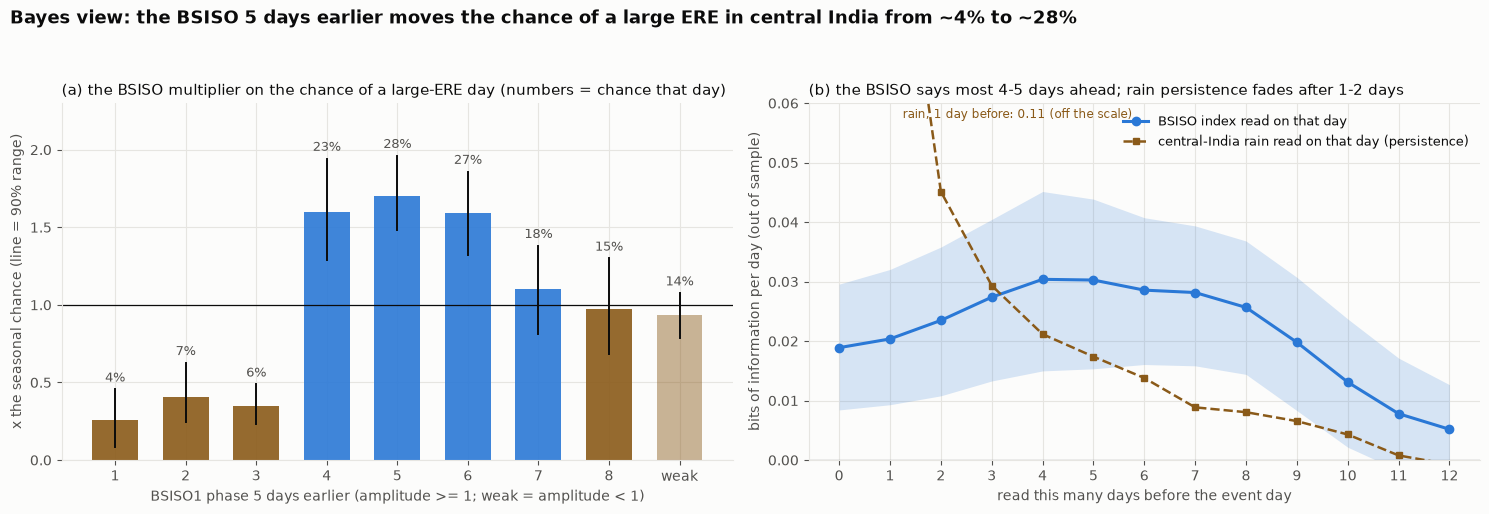

In [4]:
# %% CELL 4 -- FIGURE 2: Bayes view -- how the BSISO changes the odds of a large ERE in Central India
# prior = seasonal chance of a large-ERE day; evidence = BSISO phase 5 days earlier;
# multiplier = P(ERE | phase) / P(ERE | season) = (ERE days in that phase) / (ERE days expected from the season alone)
Yci = EV["Central India"].astype(float)
SEASON = np.clip(pd.Series(Yci.reshape(NYR, ND).mean(0)).rolling(15, center=True, min_periods=1).mean().values, 1e-4, 1)[kidx]
v5 = true_at(-5)
PH5 = np.where(np.hypot(v5[:, 0], v5[:, 1]) >= 1,
               (np.floor(np.mod(np.arctan2(v5[:, 0], -v5[:, 1]), 2 * np.pi) / (np.pi / 4)) + 1), 0).astype(int)
GROUPS = list(range(1, 9)) + [0]
YR_, SR_ = Yci.reshape(NYR, ND), SEASON.reshape(NYR, ND)
rows, MULT = [], {}
for k in GROUPS:
    s = (PH5 == k).reshape(NYR, ND)
    obs = YR_[s].sum() / SR_[s].sum()
    i = rng.integers(0, NYR, (2000, NYR))
    bt = np.array([YR_[ii][s[ii]].sum() / SR_[ii][s[ii]].sum() for ii in i])
    MULT[k] = (obs, *np.percentile(bt, [5, 95]), YR_[s].mean())
    rows.append({"BSISO 5 days earlier": f"phase {k}" if k else "weak (amp < 1)", "days": int(s.sum()),
                 "large-ERE days": int(YR_[s].sum()), "chance of a large-ERE day": f"{YR_[s].mean():.1%}",
                 "x seasonal chance": round(obs, 2), "90% range": f"{MULT[k][1]:.2f}-{MULT[k][2]:.2f}"})
print(f"Central India, prior (seasonal) chance of a large-ERE day: {Yci.mean():.1%} on average")
display(pd.DataFrame(rows).set_index("BSISO 5 days earlier"))
LAGI = []
for k in range(13):
    b_, n_ = info_by_year(Yci, true_at(-k))
    LAGI.append((b_.sum() / n_.sum(), *np.percentile(boot_info(b_, n_), [5, 95])))
LAGI = np.array(LAGI)
# persistence check: what central-India rain itself, read k days earlier, says about a large ERE on day t
cib = mask & ((lat >= 17) & (lat < 26.5))[:, None] & ((lon >= 74) & (lon <= 88.5))[None, :]
CIR = tp[:, cib].mean(axis=1)
R10 = pd.DataFrame(CIR.reshape(NYR, ND).T).rolling(10, min_periods=10).mean().values.T.ravel()


def lagged(x, k):                                                # value k days earlier in the same season
    X = np.asarray(x, float).reshape(NYR, ND)
    out = np.full_like(X, np.nan)
    out[:, k:] = X[:, :ND - k] if k else X
    return out.ravel()


RAINI = []
for k in range(1, 13):
    Xr = np.column_stack([np.log1p(lagged(CIR, k)), lagged(Yci, k), np.log1p(lagged(R10, k))])
    b_, n_ = info_by_year(Yci, Xr)
    RAINI.append(b_.sum() / n_.sum())
b_, n_ = info_by_year(Yci, X5)
obs5 = b_.sum() / n_.sum()
X5c = np.column_stack([X5, np.log1p(lagged(CIR, 5)), lagged(Yci, 5), np.log1p(lagged(R10, 5))])
bc_, nc_ = info_by_year(Yci, X5c)
br_, nr_ = info_by_year(Yci, X5c[:, 3:])
CIRC = []                                                        # within-season circular shift of the BSISO
for _ in range(200):
    sh = rng.integers(20, ND - 20, NYR)
    Xs = np.stack([np.roll(X5.reshape(NYR, ND, -1)[i], sh[i], axis=0) for i in range(NYR)]).reshape(len(times), -1)
    bs_, ns_ = info_by_year(Yci, Xs)
    CIRC.append(bs_.sum() / ns_.sum())
half = np.unique(years) <= 2012
NEI = [info_by_year(EV["Northeast"].astype(float), true_at(-k)) for k in (0, 5)]
display(pd.DataFrame({"bits per day": [
    obs5, br_.sum() / nr_.sum(), bc_.sum() / nc_.sum(), np.percentile(CIRC, 99),
    b_[half].sum() / n_[half].sum(), b_[~half].sum() / n_[~half].sum(),
    NEI[0][0].sum() / NEI[0][1].sum(), NEI[1][0].sum() / NEI[1][1].sum()]},
    index=["Central India: BSISO 5 days earlier", "Central India: rain persistence on that day (no BSISO)",
           "Central India: BSISO + rain persistence",
           "Central India: BSISO shifted in time within its own season (99th percentile of 200 shifts)",
           "Central India, 2000-2012 only", "Central India, 2013-2024 only", "Northeast: BSISO same day",
           "Northeast: BSISO 5 days earlier"]).round(4))
print(f"within-season shift test: p = {(1 + np.sum(np.array(CIRC) >= obs5)) / (len(CIRC) + 1):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
a = ax[0]
xl = [str(k) for k in range(1, 9)] + ["weak"]
for x, k in enumerate(GROUPS):
    v, lo_, hi_, p_ = MULT[k]
    a.bar(x, v, color=BLUE if v > 1 else BROWN, width=0.65, alpha=0.9 if k else 0.45)
    a.plot([x, x], [lo_, hi_], color=INK, lw=1.4)
    a.text(x, hi_ + 0.05, f"{p_:.0%}", ha="center", fontsize=9, color=INK2)
a.axhline(1, color=INK, lw=0.9)
a.set(xticks=range(9), xticklabels=xl, xlabel="BSISO1 phase 5 days earlier (amplitude >= 1; weak = amplitude < 1)",
      ylabel="x the seasonal chance (line = 90% range)", ylim=(0, 2.3))
a.set_title("(a) the BSISO multiplier on the chance of a large-ERE day (numbers = chance that day)", loc="left",
            fontsize=10.5)
a = ax[1]
a.fill_between(range(13), LAGI[:, 1], LAGI[:, 2], color=BLUE, alpha=0.18, lw=0)
a.plot(range(13), LAGI[:, 0], "o-", color=BLUE, lw=2.2, label="BSISO index read on that day")
a.plot(range(1, 13), RAINI, "s--", color=BROWN, lw=1.8, ms=5,
       label="central-India rain read on that day (persistence)")
a.legend(frameon=False, fontsize=9)
a.text(1.25, 0.0575, f"rain, 1 day before: {RAINI[0]:.2f} (off the scale)", fontsize=8.5, color=BROWN)
a.axhline(0, color=INK, lw=0.8)
a.set(xticks=range(13), xlabel="read this many days before the event day", ylim=(0, 0.06),
      ylabel="bits of information per day (out of sample)")
a.set_title("(b) the BSISO says most 4-5 days ahead; rain persistence fades after 1-2 days", loc="left",
            fontsize=10.5)
fig.suptitle("Bayes view: the BSISO 5 days earlier moves the chance of a large ERE in central India from ~4% to ~28%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(OUT, "ere02_bayes_multiplier.png"), dpi=140, bbox_inches="tight")
plt.show()

## 4. Probability maps for each BSISO phase
Where large EREs become more or less likely 5 days after the BSISO is in a given phase.

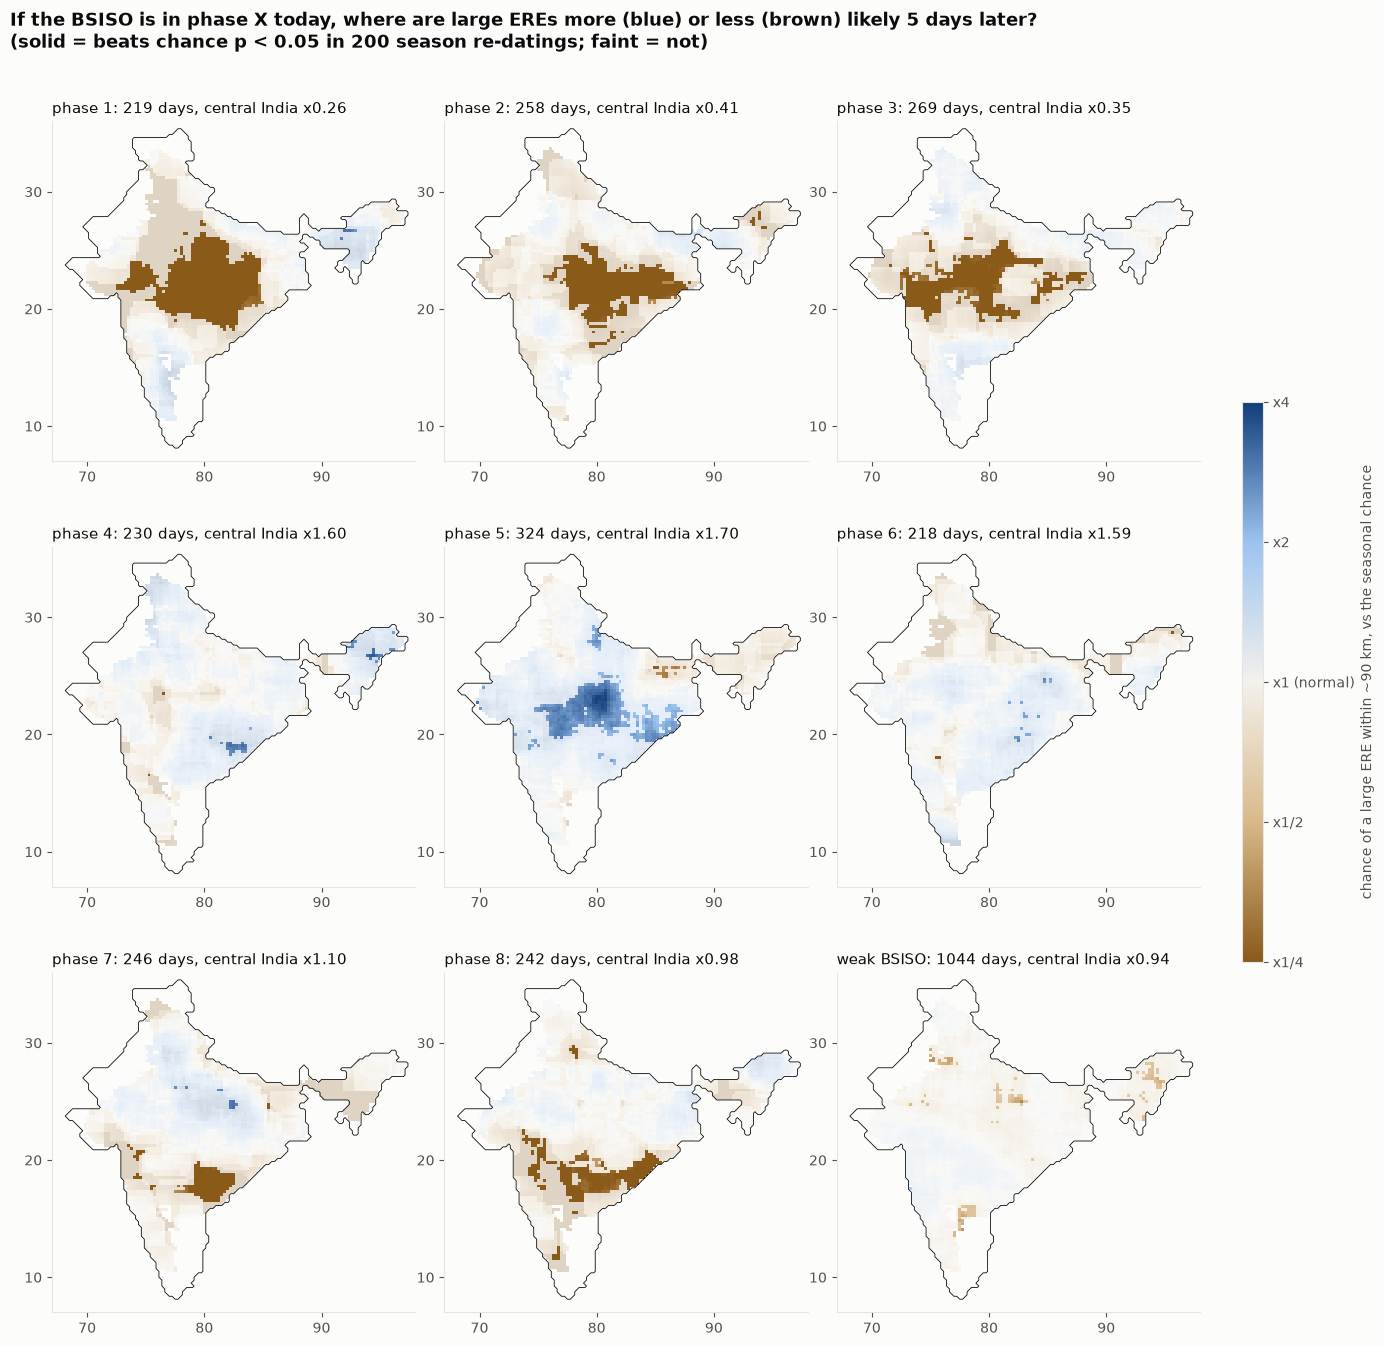

share of mapped places that beat chance (p < 0.05), by phase: ph1 24%, ph2 17%, ph3 17%, ph4 1%, ph5 15%, ph6 1%, ph7 5%, ph8 10%, weak 3%


In [5]:
# %% CELL 5 -- FIGURE 3: probability maps for each BSISO phase (where large EREs become more or less likely 5 days later)
# event at a place = a 16+ cell ERE within ~3 cells (~90 km) that day; multiplier = observed / expected from the season
NB_ = np.stack([ndimage.maximum_filter(inbig[t], size=7) for t in range(len(times))])
cells = mask & (NB_.sum(0) >= 25)                                 # places with at least 25 such days in 25 summers
N2 = NB_[:, cells].astype(np.float32); del NB_
CLM = pd.DataFrame(N2.reshape(NYR, ND, -1).mean(0)).rolling(15, center=True, min_periods=1).mean().values
D1 = np.eye(ND, dtype=np.float32)[kidx]                          # day-of-season one-hot


def phase_maps(ph):
    H = np.stack([ph == k for k in GROUPS], 1).astype(np.float32)
    return (H.T @ N2 + 0.5) / ((H.T @ D1) @ CLM + 0.5), H.sum(0)


RM, NDAYS = phase_maps(PH5)
NPM = 200
ext = np.zeros(RM.shape)
for p in PERMS[:NPM]:
    ext += np.abs(np.log(phase_maps(redate(PH5, p))[0])) >= np.abs(np.log(RM))
PM = (1 + ext) / (NPM + 1)
MAPS = np.full((len(GROUPS),) + mask.shape, np.nan); PMAPS = MAPS.copy()
MAPS[:, cells], PMAPS[:, cells] = RM, PM
cmap = LinearSegmentedColormap.from_list("bsiso", ["#8a5a19", "#d9b98a", "#f3f1ec", "#9cc3f0", "#123e7a"])
fig, ax = plt.subplots(3, 3, figsize=(14, 14))
fig.subplots_adjust(left=0.04, right=0.86, top=0.91, bottom=0.04, wspace=0.08, hspace=0.16)
for a, k, M, Pm, n in zip(ax.ravel(), GROUPS, MAPS, PMAPS, NDAYS):
    lr = np.log2(np.clip(M, 0.25, 4))
    rgba = cmap((lr + 2) / 4)
    rgba[..., 3] = np.where(np.isnan(M), 0, np.where(Pm < 0.05, 1.0, 0.25))
    a.imshow(rgba, origin="upper", extent=(lon.min(), lon.max(), lat.min(), lat.max()), interpolation="nearest")
    a.contour(lon, lat, mask.astype(float), levels=[0.5], colors=INK, linewidths=0.6)
    a.set(xlim=(67, 98), ylim=(7, 36), aspect="equal", xticks=[70, 80, 90], yticks=[10, 20, 30])
    a.grid(False)
    lbl = f"phase {k}" if k else "weak BSISO"
    a.set_title(f"{lbl}: {int(n)} days, central India x{MULT[k][0]:.2f}", loc="left", fontsize=10.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-2, 2))
cb = fig.colorbar(sm, cax=fig.add_axes([0.89, 0.3, 0.015, 0.4]), ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(["x1/4", "x1/2", "x1 (normal)", "x2", "x4"])
cb.set_label("chance of a large ERE within ~90 km, vs the seasonal chance")
fig.suptitle("If the BSISO is in phase X today, where are large EREs more (blue) or less (brown) likely 5 days later?\n"
             f"(solid = beats chance p < 0.05 in {NPM} season re-datings; faint = not)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.savefig(os.path.join(OUT, "ere03_phase_maps.png"), dpi=130, bbox_inches="tight")
plt.show()
print("share of mapped places that beat chance (p < 0.05), by phase:",
      ", ".join(f"{('ph' + str(k)) if k else 'weak'} {np.mean(p_ < 0.05):.0%}" for k, p_ in zip(GROUPS, PM)))

## 5. Clustering in the BSISO cycle: EREs vs active and break spells

,n (amp >= 1),clustering R,chance R,p,centre phase
events,,,,,
active spell days,191,0.35,0.13,0.001,5
break spell days,189,0.25,0.13,0.058,8
Central India ERE events,173,0.28,0.08,0.001,6
Northeast ERE events,57,0.34,0.15,0.004,2


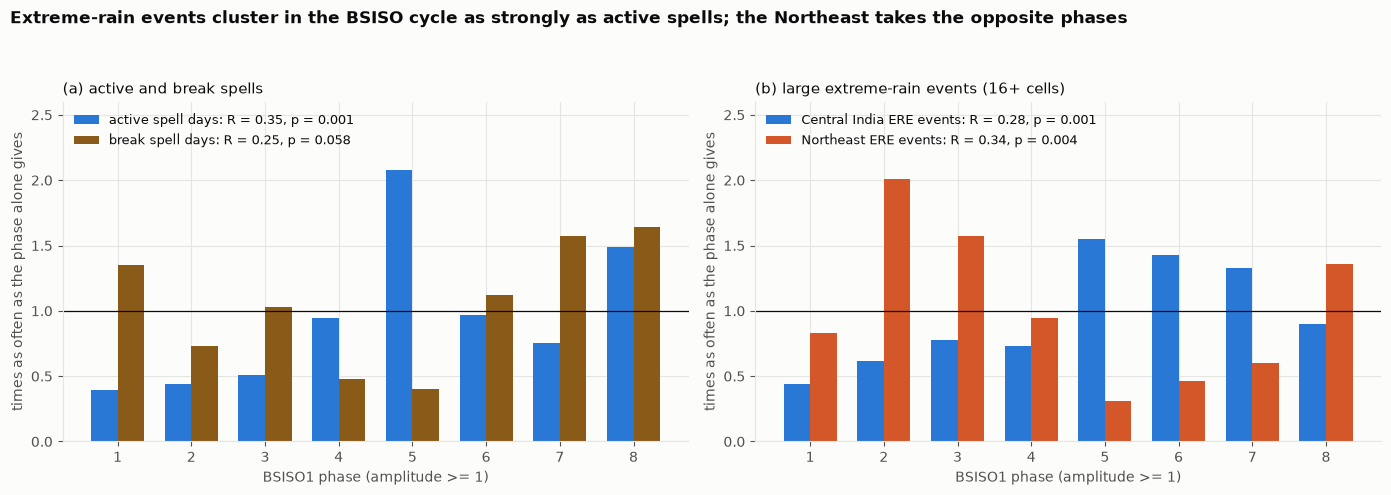

In [6]:
# %% CELL 6 -- FIGURE 4: clustering in the BSISO cycle, EREs vs active/break spells
def circ(ev, th, am):
    s = ev & (am >= 1)
    a_ = th[s]
    R = np.hypot(np.cos(a_).mean(), np.sin(a_).mean())
    sh = np.bincount((a_ // (np.pi / 4)).astype(int) % 8, minlength=8) / s.sum()
    allp = np.bincount((th[am >= 1] // (np.pi / 4)).astype(int) % 8, minlength=8) / (am >= 1).sum()
    centre = int(np.mod(np.arctan2(np.sin(a_).mean(), np.cos(a_).mean()), 2 * np.pi) // (np.pi / 4)) + 1
    return R, sh / allp, centre, s.sum()


SETS = {"active spell days": (ACT, BLUE), "break spell days": (BRK, BROWN),
        "Central India ERE events": (STARTS["Central India"], BLUE), "Northeast ERE events": (STARTS["Northeast"], ORANGE)}
rows, RAT = [], {}
for nm, (ev, c) in SETS.items():
    R, ratio, centre, n = circ(ev, THETA, AMP)
    nul = np.array([circ(ev, redate(THETA, p), redate(AMP, p))[0] for p in PERMS])
    RAT[nm] = ratio
    rows.append({"events": nm, "n (amp >= 1)": int(n), "clustering R": round(R, 2),
                 "chance R": round(nul.mean(), 2), "p": round((1 + (nul >= R).sum()) / (NPERM + 1), 3),
                 "centre phase": centre})
CLU = pd.DataFrame(rows).set_index("events")
display(CLU)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x8 = np.arange(1, 9)
for a, pair, ttl in ((ax[0], ["active spell days", "break spell days"], "(a) active and break spells"),
                     (ax[1], ["Central India ERE events", "Northeast ERE events"], "(b) large extreme-rain events (16+ cells)")):
    for nm, off in zip(pair, (-0.18, 0.18)):
        a.bar(x8 + off, RAT[nm], width=0.36, color=SETS[nm][1],
              label=f"{nm}: R = {CLU.loc[nm, 'clustering R']:.2f}, p = {CLU.loc[nm, 'p']:.3f}")
    a.axhline(1, color=INK, lw=0.9)
    a.set(xticks=x8, xlabel="BSISO1 phase (amplitude >= 1)", ylabel="times as often as the phase alone gives",
          ylim=(0, 2.6))
    a.set_title(ttl, loc="left", fontsize=10.5)
    a.legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Extreme-rain events cluster in the BSISO cycle as strongly as active spells; the Northeast takes the "
             "opposite phases", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(OUT, "ere04_clustering_vs_spells.png"), dpi=140, bbox_inches="tight")
plt.show()

## 6. Where large events sit in each phase

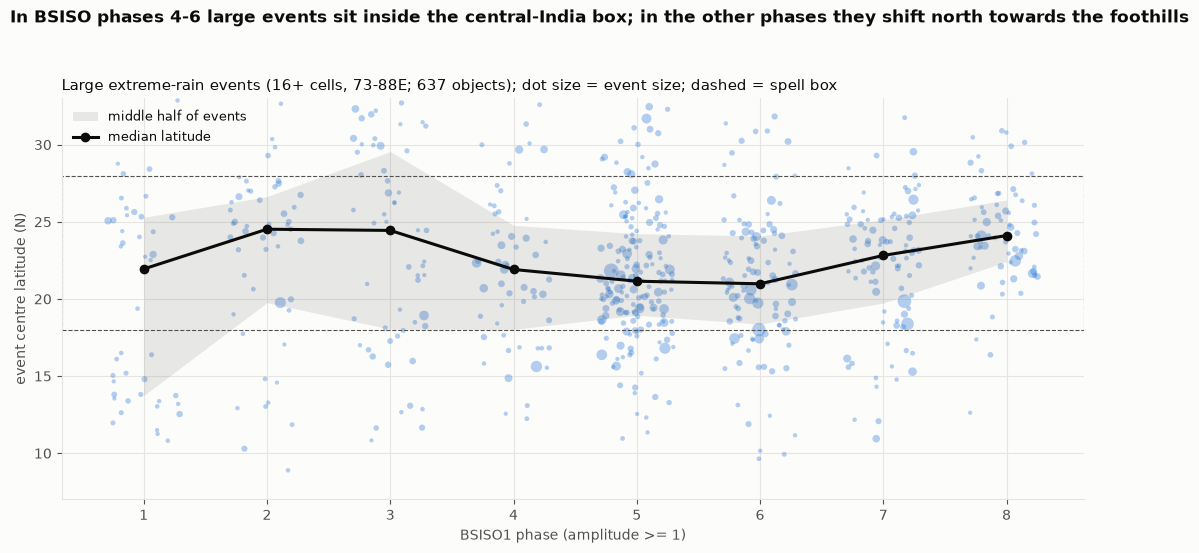

In [7]:
# %% CELL 7 -- FIGURE 5: where the events sit in each phase (central India in phases 4-6, further north otherwise)
sub = BIG[(BIG["clon"] >= 73) & (BIG["clon"] <= 88)].copy()       # Indian longitudes (Northeast excluded)
sub["ph"] = PH[sub["t"].values]
sub = sub[sub["ph"] > 0]
REP = [1, 2, 3, 4, 5, 6, 7, 8]
fig, ax = plt.subplots(figsize=(11, 5.6))
jit = rng.uniform(-0.3, 0.3, len(sub))
ax.scatter(sub["ph"] + jit, sub["clat"], s=4 + sub["size"] / 3, color=BLUE, alpha=0.35, edgecolors="none")
med = sub.groupby("ph")["clat"].median().reindex(REP)
q = sub.groupby("ph")["clat"].quantile([0.25, 0.75]).unstack().reindex(REP)
ax.fill_between(REP, q[0.25], q[0.75], color=INK2, alpha=0.12, lw=0, label="middle half of events")
ax.plot(REP, med, "o-", color=INK, lw=2.2, label="median latitude")
ax.axhspan(18, 28, color="none", ec=INK2, ls="--", lw=0.8)
ax.set(xticks=REP, xlabel="BSISO1 phase (amplitude >= 1)", ylabel="event centre latitude (N)", ylim=(7, 33))
ax.set_title(f"Large extreme-rain events (16+ cells, 73-88E; {len(sub):,} objects); dot size = event size; "
             "dashed = spell box", loc="left", fontsize=10.5)
fig.suptitle("In BSISO phases 4-6 large events sit inside the central-India box; in the other phases they shift "
             "north towards the foothills", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig(os.path.join(OUT, "ere05_latitude_by_phase.png"), dpi=140, bbox_inches="tight")
plt.show()

## 7. ERE tracks on the BSISO phase plane
Tracks come from the summer tracker's catalogue (daily objects linked by overlap). First, the 15 longest tracks that reach 16+ cells.

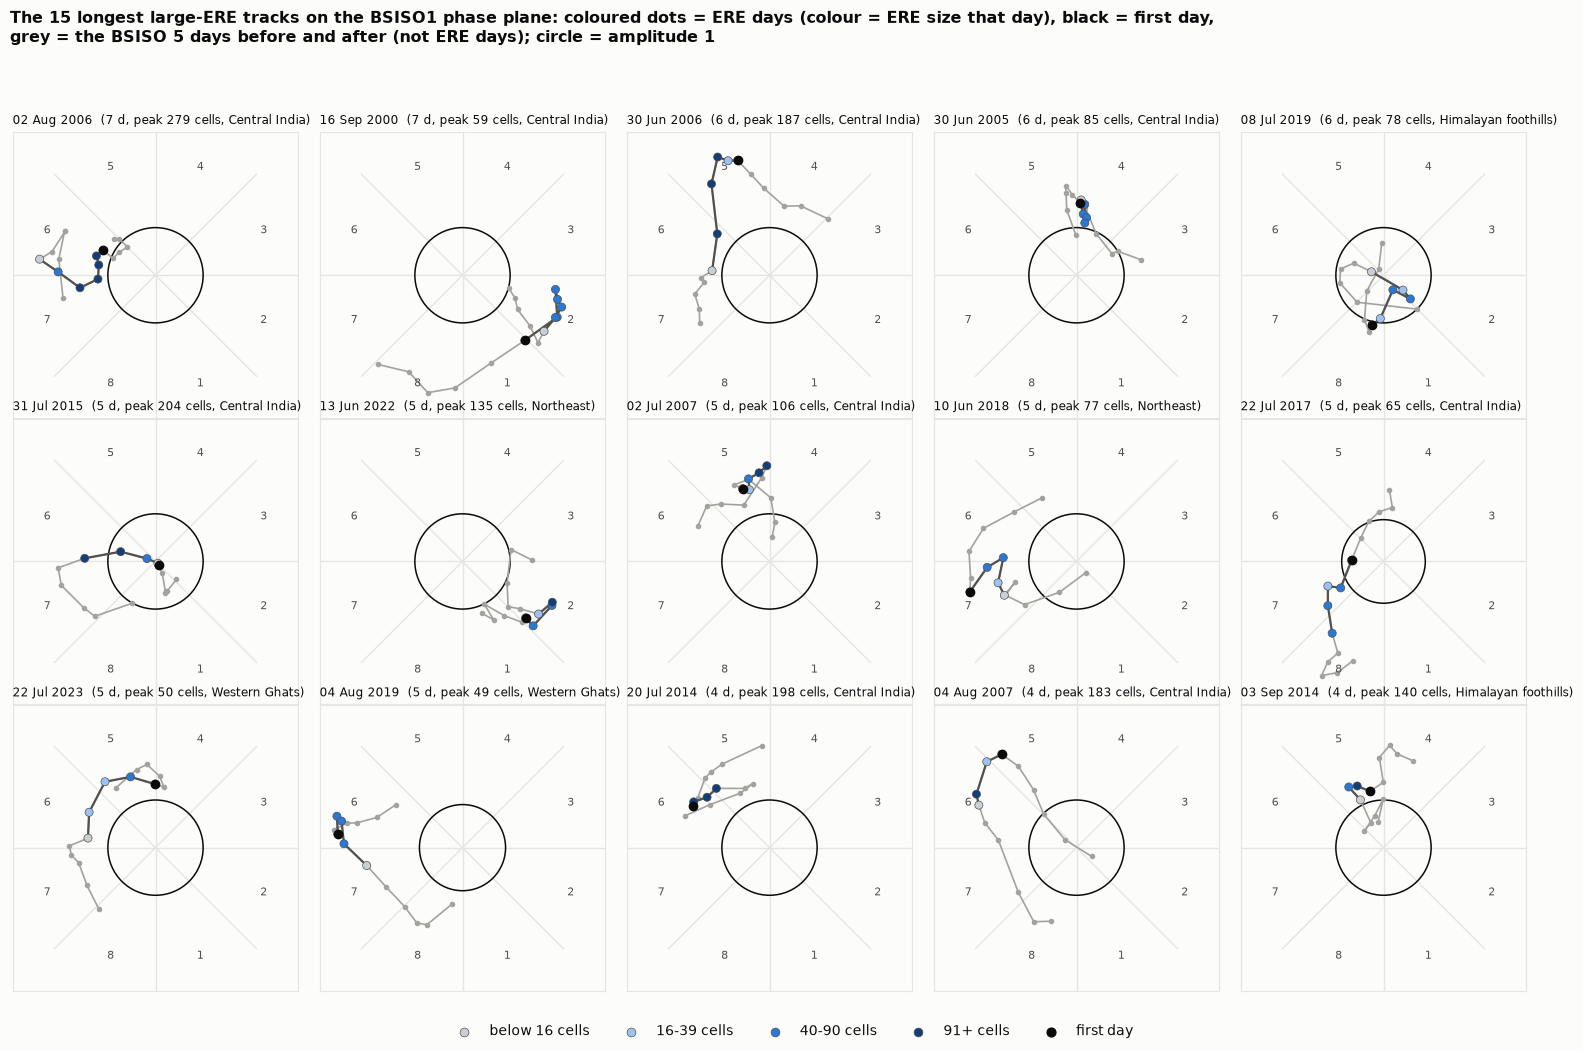

,duration,peak_size,birth_region
birth_date,,,
20060802,7,279,central_india
20000916,7,59,central_india
20060630,6,187,central_india
20050630,6,85,central_india
20190708,6,78,himalayan_foothills
20150731,5,204,central_india
20220613,5,135,northeast
20070702,5,106,central_india
20180610,5,77,northeast


In [8]:
# %% CELL 8 -- FIGURE 6: the longest large-ERE tracks on the BSISO1 phase plane (ERE track catalogue)
# tracks = the summer tracker's catalogue (daily ERE objects linked by overlap); a "large-ERE track" reaches 16+ cells
OD = pd.read_parquet(find("objdays_enriched.parquet"))            # one row per ERE object per day
TR = pd.read_parquet(find("tracks_enriched.parquet"))             # one row per ERE track
OD["date"] = pd.to_datetime(OD["date"].astype(str))
TR["birth"] = pd.to_datetime(TR["birth_date"].astype(str))
assert len(OD) == 10877 and len(TR) == 10006, "expected the summer ERE catalogue"
S1, S2 = bs["p1"], bs["p2"]                                       # full BSISO1 series (for days before/after JJAS)
phase_of = lambda x, y: (np.floor(np.mod(np.arctan2(x, -y), 2 * np.pi) / (np.pi / 4)) + 1).astype(int)
to_xy = lambda th, r: (r * np.sin(np.deg2rad(th)), -r * np.cos(np.deg2rad(th)))
LT = TR[TR["peak_size"] >= 16].copy()                             # large-ERE tracks
LT["cls"] = pd.cut(LT["peak_size"], [15, 39, 90, 99999], labels=["small", "medium", "large"]).astype(str)
SIZES = [("small", "16-39 cells", "#9cc3f0"), ("medium", "40-90 cells", BLUE), ("large", "91+ cells", "#123e7a")]
DAYC = [(0, 16, "#c9cfd6", "below 16 cells"), (16, 40, "#9cc3f0", "16-39 cells"), (40, 91, BLUE, "40-90 cells"),
        (91, 99999, "#123e7a", "91+ cells")]
dayc = lambda n: next(c for lo_, hi_, c, _ in DAYC if lo_ <= n < hi_)
REGN = {"central_india": ("Central India", BLUE), "northeast": ("Northeast", ORANGE), "west_ghats": ("Western Ghats", GREEN),
        "himalayan_foothills": ("Himalayan foothills", PURPLE), "other": ("Other", INK2)}


def phase_frame(a, rmax, fs=8, label="", box=True):
    for k in range(8):
        a.plot(*zip((0, 0), to_xy(k * 45, rmax)), color=GRID, lw=1, zorder=1)
    a.add_patch(plt.Circle((0, 0), 1, fill=False, ec=INK, lw=1.1, zorder=2))
    for k in range(1, 9):
        a.text(*to_xy((k - 0.5) * 45, rmax * 0.82), f"{label}{k}", ha="center", va="center", fontsize=fs, color=INK2)
    a.set(xlim=(-rmax, rmax), ylim=(-rmax, rmax), aspect="equal", xticks=[], yticks=[])
    a.grid(False)
    for sp in a.spines.values():
        sp.set_visible(box); sp.set_color(GRID)


LONG = LT.sort_values(["duration", "peak_size"], ascending=False).head(15)
PAD = 5
fig, ax = plt.subplots(3, 5, figsize=(15.5, 10.6))
for a, (_, tr) in zip(ax.ravel(), LONG.iterrows()):
    od = OD[OD["track_num"] == tr["track_num"]].groupby("date")["size"].sum().sort_index()
    d0, d1 = od.index[0], od.index[-1]
    g0, g1 = d0 - pd.Timedelta(days=PAD), d1 + pd.Timedelta(days=PAD)
    phase_frame(a, max(3, 1.1 * np.nanmax(np.hypot(S1[g0:g1], S2[g0:g1]))))
    a.plot(S1[g0:g1], S2[g0:g1], "o-", color="#a3a29d", lw=1.2, ms=3, zorder=2)      # one dot per day
    a.plot(S1[d0:d1], S2[d0:d1], "-", color=INK2, lw=1.6, zorder=3)
    a.scatter(S1[od.index], S2[od.index], s=34, c=[dayc(n) for n in od.values], ec=INK2, lw=0.5, zorder=4)
    a.plot(S1[d0], S2[d0], "o", color=INK, ms=6, zorder=5)
    a.set_title(f"{d0:%d %b %Y}  ({int(tr['duration'])} d, peak {int(tr['peak_size'])} cells, "
                f"{REGN[tr['birth_region']][0]})", loc="left", fontsize=8.5)
h = [plt.scatter([], [], s=40, color=c, ec=INK2, lw=0.5, label=lbl) for _, _, c, lbl in DAYC]
h += [plt.scatter([], [], s=40, color=INK, label="first day")]
fig.legend(handles=h, loc="lower center", ncol=5, frameon=False, fontsize=10)
fig.suptitle("The 15 longest large-ERE tracks on the BSISO1 phase plane: coloured dots = ERE days (colour = ERE size that "
             "day), black = first day,\n"
             f"grey = the BSISO {PAD} days before and after (not ERE days); circle = amplitude 1",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 0.93))
plt.savefig(os.path.join(OUT, "ere06_longest_tracks.png"), dpi=130, bbox_inches="tight")
plt.show()
display(LONG[["birth_date", "duration", "peak_size", "birth_region"]].set_index("birth_date"))

### Where large-ERE tracks start

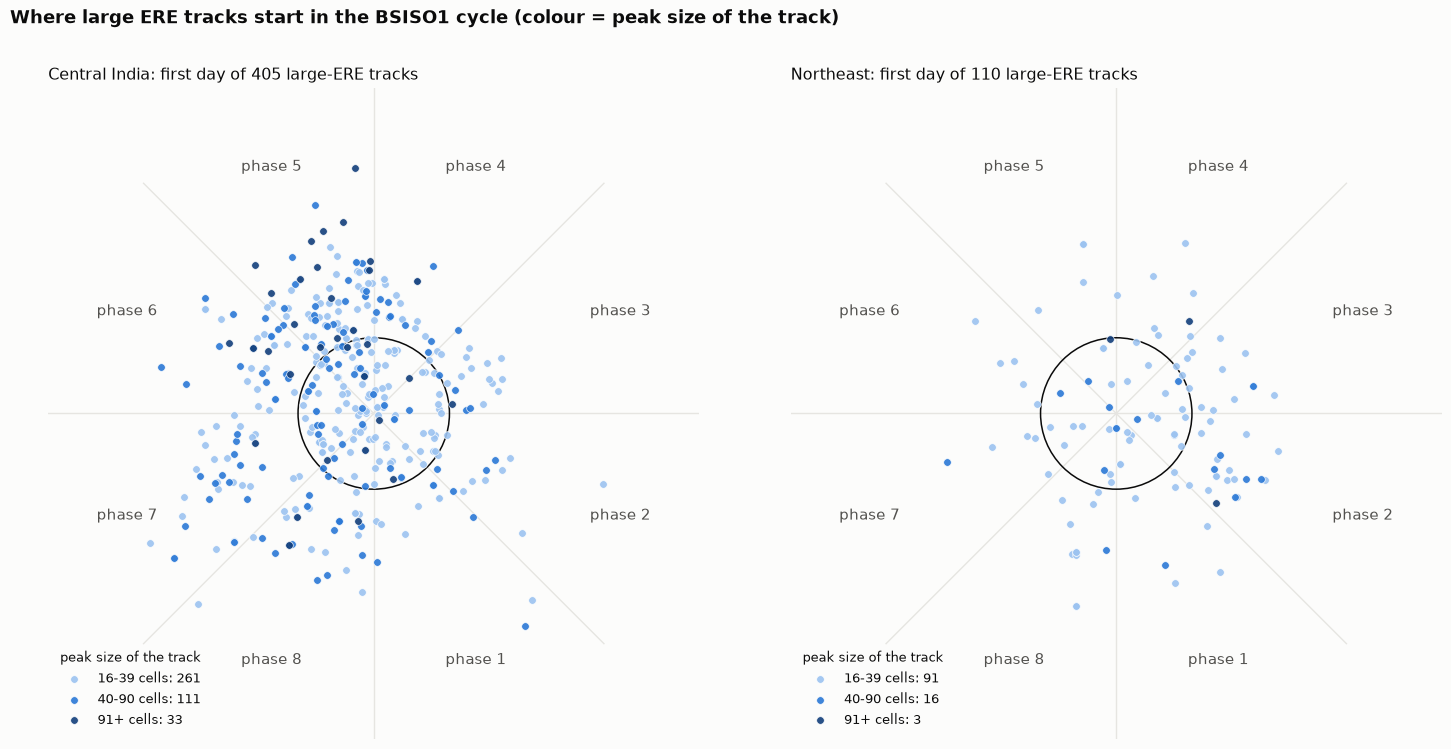

In [9]:
# %% CELL 9 -- FIGURE 7: where large-ERE tracks start on the BSISO1 phase plane, Central India vs Northeast
LT["pc1"], LT["pc2"] = S1.reindex(LT["birth"]).values, S2.reindex(LT["birth"]).values
LT["phase"] = np.where(np.hypot(LT["pc1"], LT["pc2"]) >= 1, phase_of(LT["pc1"], LT["pc2"]), 0)
fig, ax = plt.subplots(1, 2, figsize=(15, 7.6))
for a, reg in zip(ax, ("central_india", "northeast")):
    s = LT[LT["birth_region"] == reg]
    phase_frame(a, 4.3, fs=11, label="phase ", box=False)
    for z, (nm, lbl, c) in enumerate(SIZES):
        q = s[s["cls"] == nm]
        a.scatter(q["pc1"], q["pc2"], s=30, color=c, alpha=0.9, ec="white", lw=0.5, zorder=4 + z, label=f"{lbl}: {len(q)}")
    a.set_title(f"{REGN[reg][0]}: first day of {len(s)} large-ERE tracks", loc="left", fontsize=11.5)
    a.legend(frameon=False, fontsize=9.5, loc="lower left", title="peak size of the track", title_fontsize=9.5)
fig.suptitle("Where large ERE tracks start in the BSISO1 cycle (colour = peak size of the track)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig(os.path.join(OUT, "ere07_track_starts.png"), dpi=130, bbox_inches="tight")
plt.show()

### Track starts by size: counts and percentages per phase

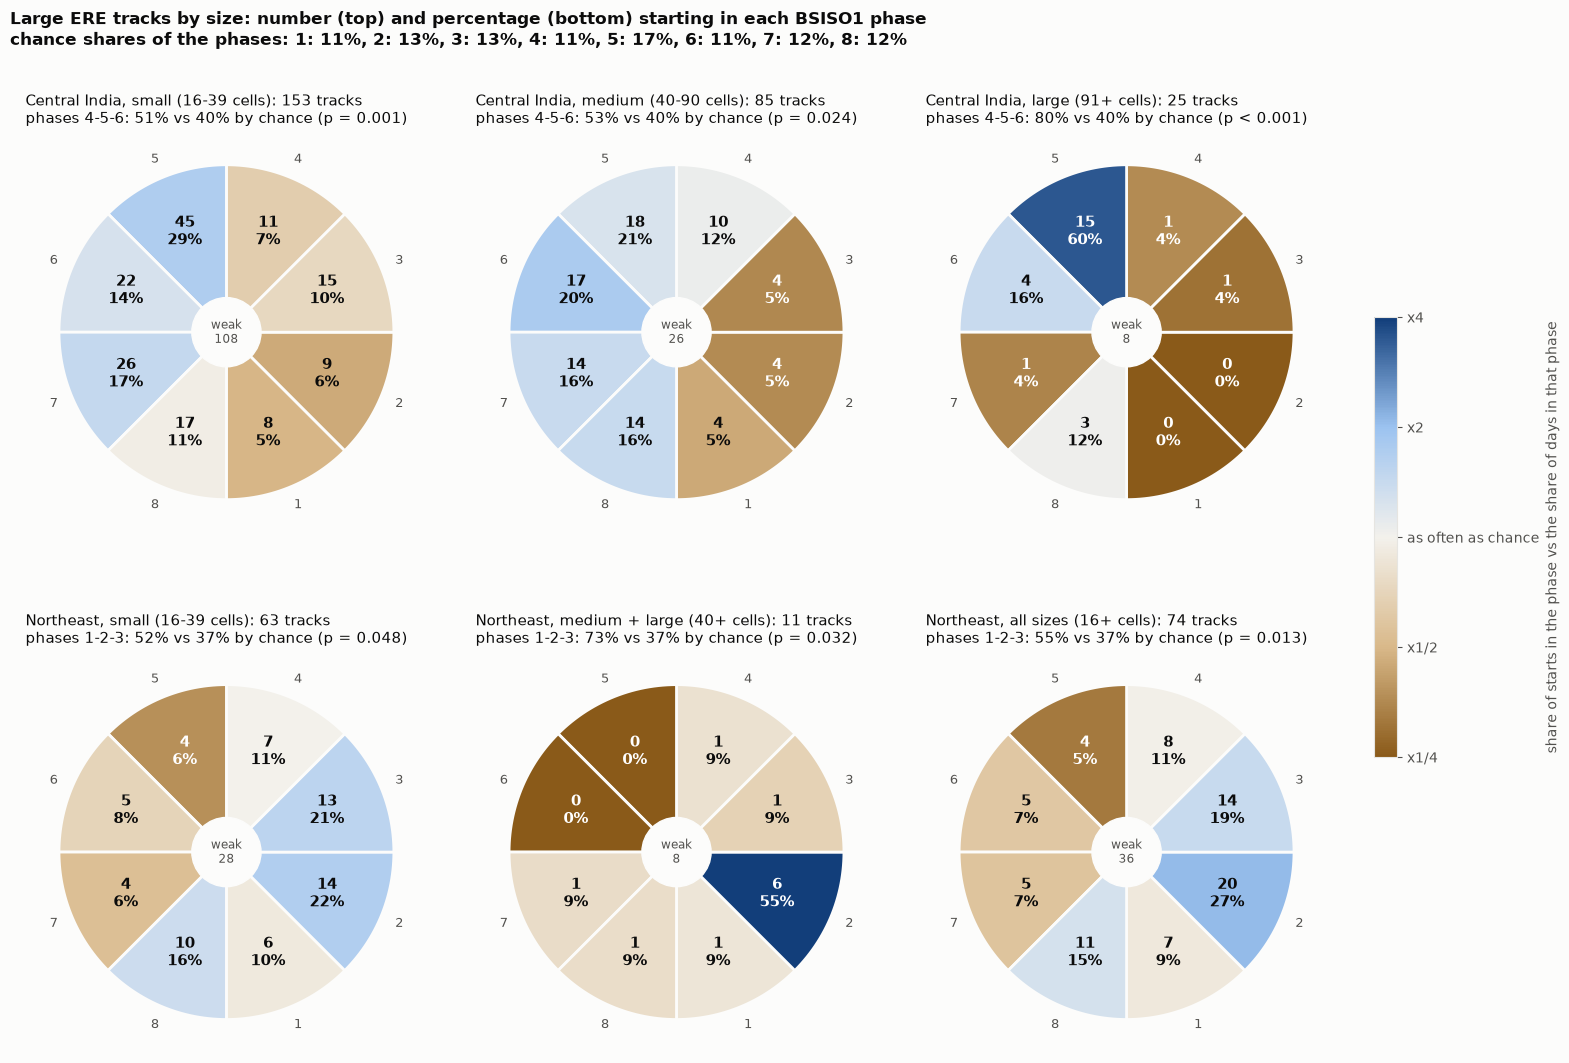

tracks (amp >= 1)  weak BSISO  \
region        size                                                        
Central India small (16-39 cells)                       153         108   
              medium (40-90 cells)                       85          26   
              large (91+ cells)                          25           8   
Northeast     small (16-39 cells)                        63          28   
              medium + large (40+ cells)                 11           8   
              all sizes (16+ cells)                      74          36   

                                              ph1       ph2       ph3  \
region        size                                                      
Central India small (16-39 cells)          8 (5%)    9 (6%)  15 (10%)   
              medium (40-90 cells)         4 (5%)    4 (5%)    4 (5%)   
              large (91+ cells)            0 (0%)    0 (0%)    1 (4%)   
Northeast     small (16-39 cells)         6 (10%)  14 (22%)  13 (21%)   
              medium + large (40+ cells)   1 (9%)   6 (55%)    1 (9%)   
              all sizes (16+ cells)        7 (9%)  20 (27%)  14 (19%)   

                                               ph4       ph5       ph6  \
region        size                                                       
Central India small (16-39 cells)          11 (7%)  45 (29%)  22 (14%)   
              medium (40-90 cells)        10 (12%)  18 (21%)  17 (20%)   
              large (91+ cells)             1 (4%)  15 (60%)   4 (16%)   
Northeast     small (16-39 cells)          7 (11%)    4 (6%)    5 (8%)   
              medium + large (40+ cells)    1 (9%)    0 (0%)    0 (0%)   
              all sizes (16+ cells)        8 (11%)    4 (5%)    5 (7%)   

                                               ph7       ph8 favoured share  \
region        size                                                            
Central India small (16-39 cells)         26 (17%)  17 (11%)            51%   
              medium (40-90 cells)        14 (16%)  14 (16%)            53%   
              large (91+ cells)             1 (4%)   3 (12%)            80%   
Northeast     small (16-39 cells)           4 (6%)  10 (16%)            52%   
              medium + large (40+ cells)    1 (9%)    1 (9%)            73%   
              all sizes (16+ cells)         5 (7%)  11 (15%)            55%   

                                               p  
region        size                                
Central India small (16-39 cells)         0.0015  
              medium (40-90 cells)        0.0240  
              large (91+ cells)           0.0005  
Northeast     small (16-39 cells)         0.0480  
              medium + large (40+ cells)  0.0320  
              all sizes (16+ cells)       0.0130

In [10]:
# %% CELL 10 -- FIGURE 8: track starts by size and BSISO1 phase, as counts and percentages (season re-dating p-values)
JJ = bs.index.month.isin([6, 7, 8, 9]) & (bs.index.year >= years.min()) & (bs.index.year <= years.max())
pj = phase_of(S1[JJ], S2[JJ])[np.hypot(S1[JJ], S2[JJ]) >= 1]
CH = np.bincount(pj, minlength=9)[1:] / len(pj)                   # share of strong-BSISO JJAS days in each phase
YRS_ = np.unique(years)
SEASON_PC = {y: (S1.reindex(pd.date_range(f"{y}-06-01", f"{y}-09-30")).values,
                 S2.reindex(pd.date_range(f"{y}-06-01", f"{y}-09-30")).values) for y in YRS_}


def share(s):
    st = s[s["phase"] > 0]
    return np.bincount(st["phase"], minlength=9)[1:], len(st), int((s["phase"] == 0).sum())


def p_fav(s, fav, n=2000):
    """share of starts in the favoured phases, and its season re-dating p-value."""
    c_, n_, _ = share(s)
    obs = c_[np.array(fav) - 1].sum() / max(n_, 1)
    yy = s["birth"].dt.year.values
    dd = (s["birth"] - pd.to_datetime(s["birth"].dt.year.astype(str) + "-06-01")).dt.days.values
    hit = 0
    for _ in range(n):
        perm = dict(zip(YRS_, rng.permutation(YRS_)))
        x = np.array([SEASON_PC[perm[y]][0][d] for y, d in zip(yy, dd)])
        v = np.array([SEASON_PC[perm[y]][1][d] for y, d in zip(yy, dd)])
        ok_ = np.hypot(x, v) >= 1
        hit += np.isin(phase_of(x[ok_], v[ok_]), fav).mean() >= obs
    return obs, (1 + hit) / (n + 1)


WCM = LinearSegmentedColormap.from_list("w", [BROWN, "#d9b98a", "#f3f1ec", "#9cc3f0", "#123e7a"])
FAV = {"central_india": [4, 5, 6], "northeast": [1, 2, 3]}
PANELS = {"central_india": [("small", "16-39 cells", ["small"]), ("medium", "40-90 cells", ["medium"]),
                            ("large", "91+ cells", ["large"])],
          "northeast": [("small", "16-39 cells", ["small"]), ("medium + large", "40+ cells", ["medium", "large"]),
                        ("all sizes", "16+ cells", ["small", "medium", "large"])]}
fig, ax = plt.subplots(2, 3, figsize=(15.5, 11))
fig.subplots_adjust(left=0.02, right=0.86, top=0.88, bottom=0.02, wspace=0.12, hspace=0.22)
rows = []
for i, reg in enumerate(("central_india", "northeast")):
    for j, (nm, lbl, keep) in enumerate(PANELS[reg]):
        a = ax[i, j]
        s = LT[(LT["birth_region"] == reg) & (LT["cls"].isin(keep))]
        cnt, n, weak = share(s)
        sh = cnt / max(n, 1)
        obs, p = p_fav(s, FAV[reg])
        for k in range(8):
            xs, ys = to_xy(np.linspace(k * 45, (k + 1) * 45, 30), 3.0)
            lr = np.log2(max(sh[k] / CH[k], 0.125))
            a.fill(np.r_[0, xs, 0], np.r_[0, ys, 0], color=WCM(np.clip((lr + 2) / 4, 0, 1)), ec=SURF, lw=2, zorder=1)
            a.text(*to_xy((k + 0.5) * 45, 1.95), f"{cnt[k]}\n{sh[k]:.0%}", ha="center", va="center", fontsize=10.5,
                   fontweight="bold", color="white" if abs(lr) > 1.2 else INK, zorder=3)
            a.text(*to_xy((k + 0.5) * 45, 3.35), f"{k + 1}", ha="center", va="center", fontsize=9, color=INK2)
        a.add_patch(plt.Circle((0, 0), 0.62, color=SURF, zorder=2))
        a.text(0, 0, f"weak\n{weak}", ha="center", va="center", fontsize=8.5, color=INK2, zorder=3)
        a.set(xlim=(-3.6, 3.6), ylim=(-3.6, 3.6), aspect="equal", xticks=[], yticks=[])
        a.grid(False)
        for sp in a.spines.values():
            sp.set_visible(False)
        fv = "-".join(map(str, FAV[reg]))
        a.set_title(f"{REGN[reg][0]}, {nm} ({lbl}): {n} tracks\nphases {fv}: {obs:.0%} vs "
                    f"{CH[np.array(FAV[reg]) - 1].sum():.0%} by chance ({'p < 0.001' if p < 0.001 else f'p = {p:.3f}'})",
                    loc="left", fontsize=10.5)
        rows.append({"region": REGN[reg][0], "size": f"{nm} ({lbl})", "tracks (amp >= 1)": n, "weak BSISO": weak,
                     **{f"ph{k + 1}": f"{cnt[k]} ({sh[k]:.0%})" for k in range(8)}, "favoured share": f"{obs:.0%}",
                     "p": round(p, 4)})
sm = plt.cm.ScalarMappable(cmap=WCM, norm=plt.Normalize(-2, 2))
cb = fig.colorbar(sm, cax=fig.add_axes([0.89, 0.3, 0.015, 0.4]), ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(["x1/4", "x1/2", "as often as chance", "x2", "x4"])
cb.set_label("share of starts in the phase vs the share of days in that phase")
fig.suptitle("Large ERE tracks by size: number (top) and percentage (bottom) starting in each BSISO1 phase\n"
             "chance shares of the phases: " + ", ".join(f"{k + 1}: {CH[k]:.0%}" for k in range(8)),
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.savefig(os.path.join(OUT, "ere08_track_size_by_phase.png"), dpi=130, bbox_inches="tight")
plt.show()
display(pd.DataFrame(rows).set_index(["region", "size"]))

### Average BSISO path around the start of a track, by size

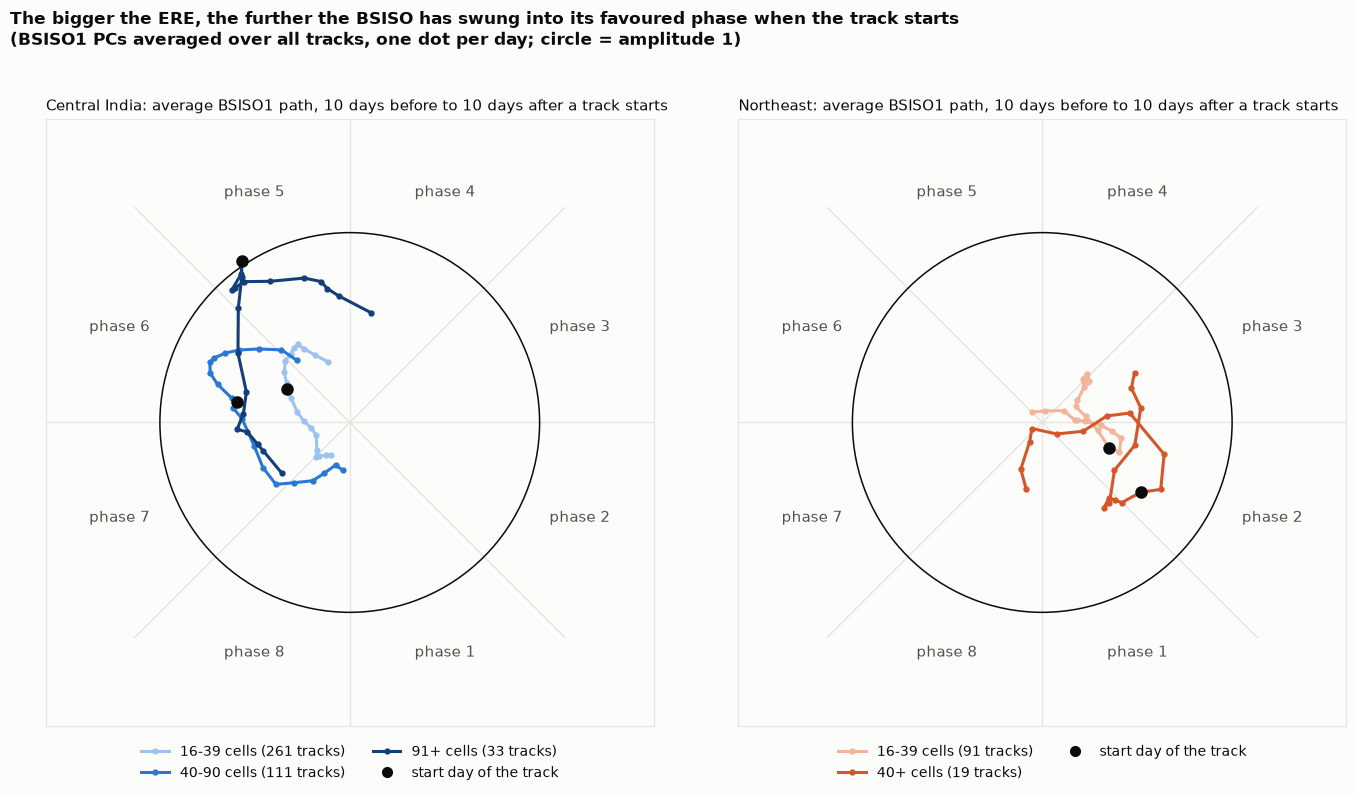

In [11]:
# %% CELL 11 -- FIGURE 9: average BSISO1 path around the start of a track, by size class
LAGS = np.arange(-10, 11)


def mean_path(sel):
    X = np.array([[S1.get(d + pd.Timedelta(days=int(L)), np.nan) for L in LAGS] for d in sel["birth"]])
    Y = np.array([[S2.get(d + pd.Timedelta(days=int(L)), np.nan) for L in LAGS] for d in sel["birth"]])
    return np.nanmean(X, 0), np.nanmean(Y, 0)


PATHS = {"central_india": [("16-39 cells", ["small"], "#9cc3f0"), ("40-90 cells", ["medium"], BLUE),
                           ("91+ cells", ["large"], "#123e7a")],
         "northeast": [("16-39 cells", ["small"], "#f2b49a"), ("40+ cells", ["medium", "large"], ORANGE)]}
fig, ax = plt.subplots(1, 2, figsize=(14, 7.6))
for a, (reg, grp) in zip(ax, PATHS.items()):
    phase_frame(a, 1.6, fs=11, label="phase ")
    for nm, keep, c in grp:
        sel = LT[(LT["birth_region"] == reg) & (LT["cls"].isin(keep))]
        mx, my = mean_path(sel)
        a.plot(mx, my, "o-", color=c, lw=2.2, ms=3.5, zorder=4, label=f"{nm} ({len(sel)} tracks)")
        a.plot(mx[LAGS == 0], my[LAGS == 0], "o", color=INK, ms=8, zorder=6)
    a.plot([], [], "o", color=INK, ms=7, label="start day of the track")
    a.set_title(f"{REGN[reg][0]}: average BSISO1 path, 10 days before to 10 days after a track starts",
                loc="left", fontsize=11)
    a.legend(frameon=False, fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2)
fig.suptitle("The bigger the ERE, the further the BSISO has swung into its favoured phase when the track starts\n"
             "(BSISO1 PCs averaged over all tracks, one dot per day; circle = amplitude 1)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(OUT, "ere09_mean_path_by_size.png"), dpi=130, bbox_inches="tight")
plt.show()

## 8. Does a stronger BSISO bring more large extremes?

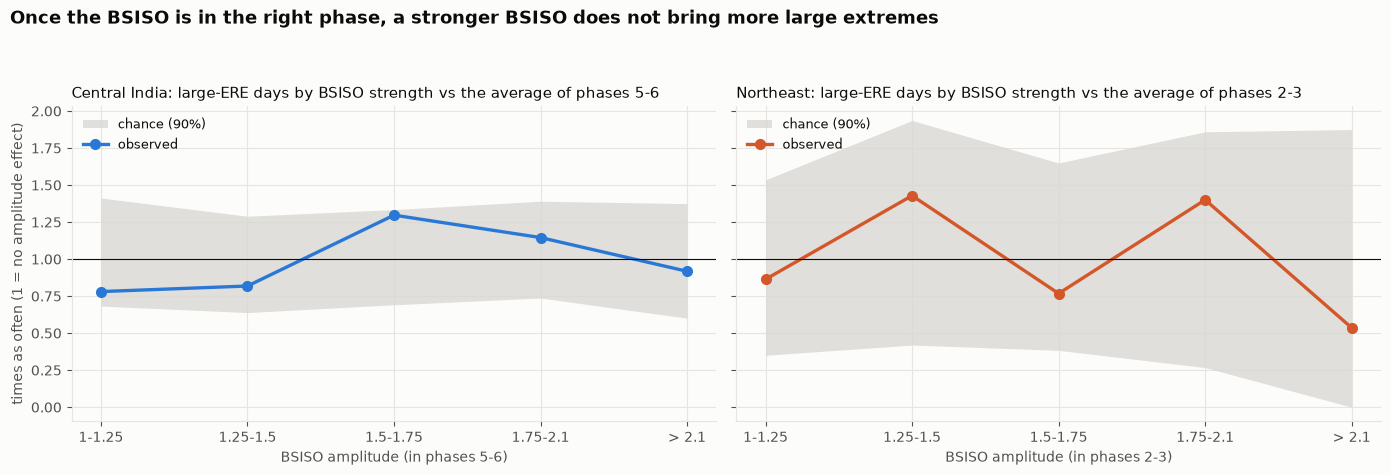

,strong (>= 1.75) vs moderate (1-1.75),p (two-sided)
region,,
Central India,x1.05,0.814
Northeast,x1.06,0.915


In [12]:
# %% CELL 12 -- FIGURE 10: a stronger BSISO does not bring more large extremes (contrast with Lee et al. 2017)
ABINS = [1, 1.25, 1.5, 1.75, 2.1, 9]
FAVP = {"Central India": [5, 6], "Northeast": [2, 3]}


def amp_profile(ev, ph, am, fav):
    base = ev[np.isin(ph, fav) & (am >= 1)].mean()               # average of the favourable phases
    out = []
    for lo_, hi_ in zip(ABINS[:-1], ABINS[1:]):
        s = np.isin(ph, fav) & (am >= lo_) & (am < hi_)
        out.append(ev[s].mean() / base)
    return np.array(out)


labels_ = [f"{lo_:g}-{hi_:g}" if hi_ < 9 else f"> {lo_:g}" for lo_, hi_ in zip(ABINS[:-1], ABINS[1:])]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
rows = []
for a, (reg, fav) in zip(ax, FAVP.items()):
    ev = EV[reg].astype(float)
    obs = amp_profile(ev, PHASE, AMP, fav)
    nul = np.array([amp_profile(ev, redate(PHASE, p), redate(AMP, p), fav) for p in PERMS])
    xs_ = np.arange(len(obs))
    a.fill_between(xs_, *np.percentile(nul, [5, 95], axis=0), color=NULLC, alpha=0.8, lw=0, label="chance (90%)")
    a.plot(xs_, obs, "o-", color=BLUE if reg == "Central India" else ORANGE, lw=2.4, ms=7, label="observed")
    a.axhline(1, color=INK, lw=0.8)
    a.set(xticks=xs_, xticklabels=labels_, xlabel=f"BSISO amplitude (in phases {'-'.join(map(str, fav))})")
    a.set_title(f"{reg}: large-ERE days by BSISO strength vs the average of phases {'-'.join(map(str, fav))}",
                loc="left", fontsize=10.5)
    a.legend(frameon=False, fontsize=9, loc="upper left")
    s1 = np.isin(PHASE, fav) & (AMP >= 1) & (AMP < 1.75)
    s2 = np.isin(PHASE, fav) & (AMP >= 1.75)
    r_ = ev[s2].mean() / ev[s1].mean()
    rn = np.array([ev[np.isin(redate(PHASE, p), fav) & (redate(AMP, p) >= 1.75)].mean() /
                   ev[np.isin(redate(PHASE, p), fav) & (redate(AMP, p) >= 1) & (redate(AMP, p) < 1.75)].mean()
                   for p in PERMS])
    rows.append({"region": reg, "strong (>= 1.75) vs moderate (1-1.75)": f"x{r_:.2f}",
                 "p (two-sided)": round((1 + (np.abs(np.log(rn)) >= abs(np.log(r_))).sum()) / (NPERM + 1), 3)})
ax[0].set_ylabel("times as often (1 = no amplitude effect)")
fig.suptitle("Once the BSISO is in the right phase, a stronger BSISO does not bring more large extremes",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig(os.path.join(OUT, "ere10_amplitude.png"), dpi=140, bbox_inches="tight")
plt.show()
display(pd.DataFrame(rows).set_index("region"))

## 9. The forecast target: daily ERE size class in central India
No ERE / 16-39 / 40-90 / 91+ cells; skill against the seasonal chance for 1-14 days ahead.

chance of each class on a day, by the BSISO phase 5 days earlier (x = multiplier on the seasonal chance)
all days: no ERE 84.7%, 16-39 cells 8.9%, 40-90 cells 5.0%, 91+ cells 1.4%


,days,no ERE,16-39 cells,40-90 cells,91+ cells
BSISO 5 days earlier,,,,,
phase 1,219,96.3% (x1.12),2.7% (x0.34),0.9% (x0.19),0.0% (x0.00)
phase 2,258,93.4% (x1.11),4.7% (x0.49),1.9% (x0.37),0.0% (x0.00)
phase 3,269,94.4% (x1.12),4.5% (x0.46),0.7% (x0.16),0.4% (x0.25)
phase 4,230,76.5% (x0.90),16.5% (x1.92),5.2% (x1.11),1.7% (x1.24)
phase 5,324,71.6% (x0.86),13.0% (x1.32),10.5% (x1.96),4.9% (x3.19)
phase 6,218,72.9% (x0.88),14.7% (x1.49),9.2% (x1.63),3.2% (x2.08)
phase 7,246,82.1% (x0.98),7.3% (x0.78),10.2% (x1.90),0.4% (x0.28)
phase 8,242,84.7% (x1.00),9.9% (x1.10),4.5% (x0.88),0.8% (x0.56)
weak (amp < 1),1044,86.4% (x1.01),8.4% (x1.01),3.9% (x0.82),1.2% (x0.90)


,bits per day,share of the uncertainty removed
forecast,,
perfect BSISO 5 days before,0.0303,5.0%
lead 10: BSISO on the issue day,0.0131,2.2%
lead 10: lasso BSISO forecast,0.0190,3.2%


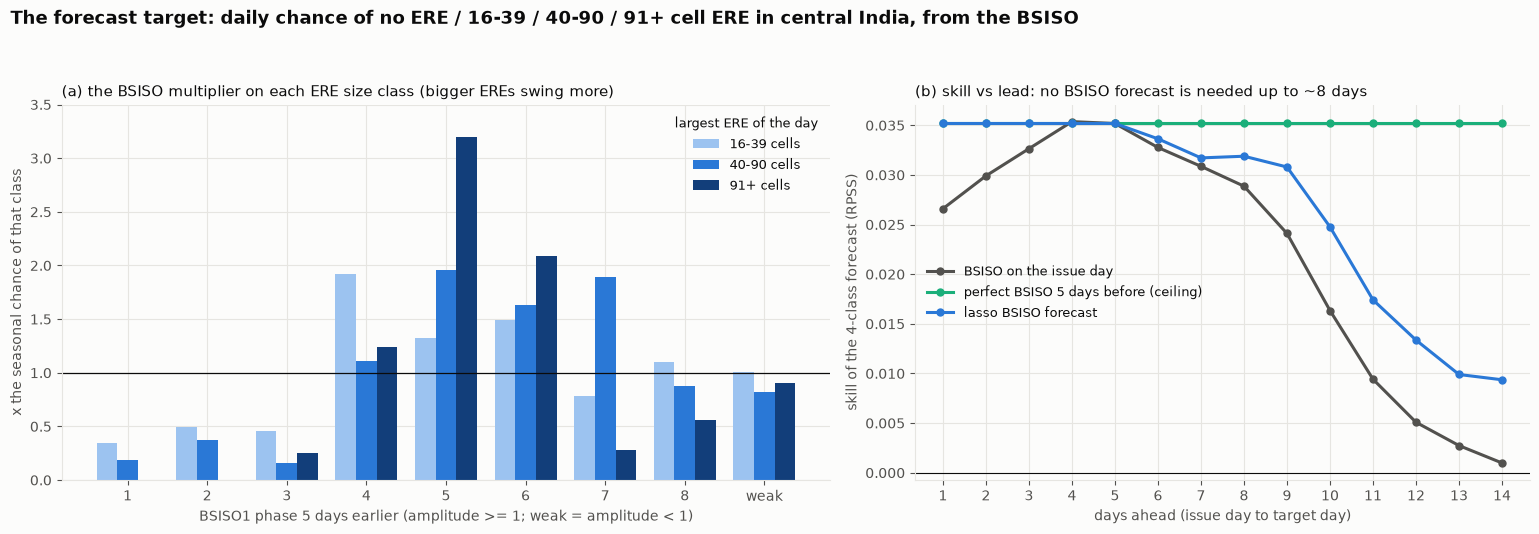

,1 d,2 d,3 d,4 d,5 d,6 d,7 d,8 d,9 d,10 d,11 d,12 d,13 d,14 d
BSISO on the issue day,0.027,0.030,0.033,0.035,0.035,0.033,0.031,0.029,0.024,0.016,0.009,0.005,0.003,0.001
perfect BSISO 5 days before (ceiling),0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035,0.035
lasso BSISO forecast,0.035,0.035,0.035,0.035,0.035,0.034,0.032,0.032,0.031,0.025,0.017,0.013,0.010,0.009


In [13]:
# %% CELL 13 -- FIGURE 11: daily forecast of the ERE size class in Central India (no ERE / 16-39 / 40-90 / 91+ cells)
# class of a day = the size of its largest 16+ cell ERE centred in Central India. Forecast = cumulative logistic
# models (>= 16, >= 40, >= 91 cells) on the BSISO 5 days before the target day; each summer predicted from the other 24.
# RPSS = skill of the whole 4-class forecast against the seasonal chance (0 = no better, 1 = perfect).
CIB = BIG[BIG["region"] == "Central India"]
MXS = np.zeros(len(times))
np.maximum.at(MXS, CIB["t"].values, CIB["size"].values)
CLS4 = np.digitize(MXS, [16, 40, 91])
CNAMES = ["no ERE", "16-39 cells", "40-90 cells", "91+ cells"]
CCOL = [NULLC, "#9cc3f0", BLUE, "#123e7a"]
YC = [(CLS4 >= t).astype(float) for t in (1, 2, 3)]


def class_forecast(X):
    PMs, PRs, G = [], [], np.ones(len(times), bool)
    for y in YC:
        pm, pr, g = loyo(y, X)
        PMs.append(pm); PRs.append(pr); G &= g
    return np.minimum.accumulate(np.array(PMs), 0), np.minimum.accumulate(np.array(PRs), 0), G


def rpss4(PMs, PRs, G):
    Y = np.array(YC)
    f = lambda Q: ((Q[:, G] - Y[:, G]) ** 2).sum(0).mean()
    return 1 - f(PMs) / f(PRs)


rows, CMULT = [], {}
for k in GROUPS:
    s = PH5 == k
    r = {"BSISO 5 days earlier": f"phase {k}" if k else "weak (amp < 1)", "days": int(s.sum())}
    for c in range(4):
        yc = (CLS4 == c).astype(float)
        clim = np.clip(pd.Series(yc.reshape(NYR, ND).mean(0)).rolling(15, center=True, min_periods=1).mean().values,
                       1e-6, 1)[kidx]
        CMULT[(k, c)] = yc[s].sum() / clim[s].sum()
        r[CNAMES[c]] = f"{yc[s].mean():.1%} (x{CMULT[(k, c)]:.2f})"
    rows.append(r)
print("chance of each class on a day, by the BSISO phase 5 days earlier (x = multiplier on the seasonal chance)")
print("all days: " + ", ".join(f"{CNAMES[c]} {np.mean(CLS4 == c):.1%}" for c in range(4)))
display(pd.DataFrame(rows).set_index("BSISO 5 days earlier"))

LEADS = np.arange(1, 15)
SRC = {"BSISO on the issue day": lambda L: true_at(-L), "perfect BSISO 5 days before (ceiling)": lambda L: X5}
if LZ is not None:
    SRC["lasso BSISO forecast"] = lambda L: lasso_at(L - 5, -5) if L > 5 else X5
SK = {k: [rpss4(*class_forecast(fx(L))) for L in LEADS] for k, fx in SRC.items()}

# how much of the day-to-day uncertainty each forecast removes (any large ERE: yes/no), lead 10
rows = []
for nm, X in (("perfect BSISO 5 days before", X5), ("lead 10: BSISO on the issue day", true_at(-10))) + \
             ((("lead 10: lasso BSISO forecast", lasso_at(5, -5)),) if LZ is not None else ()):
    pm, pr, g = loyo(YC[0], X)
    a_, r_, t_ = np.clip(pm[g], 1e-4, 1 - 1e-4), np.clip(pr[g], 1e-4, 1 - 1e-4), YC[0][g]
    unc = np.mean(-(t_ * np.log2(r_) + (1 - t_) * np.log2(1 - r_)))
    ig = np.mean(t_ * np.log2(a_ / r_) + (1 - t_) * np.log2((1 - a_) / (1 - r_)))
    rows.append({"forecast": nm, "bits per day": round(ig, 4), "share of the uncertainty removed": f"{ig / unc:.1%}"})
display(pd.DataFrame(rows).set_index("forecast"))

fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.4), gridspec_kw={"width_ratios": [1.25, 1]})
a = ax[0]
xg = np.arange(len(GROUPS))
for j, c in enumerate((1, 2, 3)):
    a.bar(xg + (j - 1) * 0.26, [CMULT[(k, c)] for k in GROUPS], width=0.26, color=CCOL[c], label=CNAMES[c])
a.axhline(1, color=INK, lw=0.9)
a.set(xticks=xg, xticklabels=[str(k) if k else "weak" for k in GROUPS], ylim=(0, 3.5),
      xlabel="BSISO1 phase 5 days earlier (amplitude >= 1; weak = amplitude < 1)", ylabel="x the seasonal chance of that class")
a.set_title("(a) the BSISO multiplier on each ERE size class (bigger EREs swing more)", loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=9.5, title="largest ERE of the day", title_fontsize=9.5)
a = ax[1]
for (k, v), c in zip(SK.items(), (INK2, GREEN, BLUE)):
    a.plot(LEADS, v, "o-", color=c, lw=2.2, ms=5, label=k)
a.axhline(0, color=INK, lw=0.8)
a.set(xticks=LEADS, xlabel="days ahead (issue day to target day)", ylabel="skill of the 4-class forecast (RPSS)")
a.set_title("(b) skill vs lead: no BSISO forecast is needed up to ~8 days", loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=9.5)
fig.suptitle("The forecast target: daily chance of no ERE / 16-39 / 40-90 / 91+ cell ERE in central India, from the BSISO",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(OUT, "ere11_daily_size_forecast.png"), dpi=140, bbox_inches="tight")
plt.show()
display(pd.DataFrame(SK, index=[f"{L} d" for L in LEADS]).T.round(3))